In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset (adjust filename to your actual CSV name)
df = pd.read_csv("data/Irrigation_Scheduling_Dataset.csv")

print("Shape:", df.shape)
df.head()

Shape: (7000, 27)


,Field_ID,Crop_Type,Growth_Stage,Soil_Type,Day_of_Year,Time_of_Day,Soil_Moisture,Soil_Temperature,Soil_pH,Soil_EC,...,Leaf_Area_Index,Crop_Coefficient,Field_Slope,Water_Availability,Previous_Irrigation_Amount,Days_Since_Last_Irrigation,Historical_Soil_Moisture,Evaporation_Demand,Water_Stress_Index,Irrigation_Action
0,52,Wheat,Flowering,Clay,306,16,34.653372,28.475039,7.22,1.63,...,4.19,1.15,4.86,65.38,10.50,7,24.66,52.41,76.23,Medium
1,93,Rice,Maturity,Sandy,89,13,33.868557,23.155641,6.57,1.28,...,1.52,0.75,6.56,27.17,43.60,3,29.82,36.76,72.15,High
2,15,Groundnut,Fruiting,Clay,155,14,42.952956,23.344024,7.57,2.21,...,3.94,1.05,7.16,79.06,12.54,10,40.47,43.20,71.10,No_Irrigation
3,72,Wheat,Vegetative,Loamy,233,14,34.452554,29.874891,7.20,1.00,...,3.47,0.90,7.37,82.31,12.90,12,22.52,45.19,72.61,Medium
4,61,Sugarcane,Flowering,Sandy,193,14,20.163457,29.949118,6.24,1.78,...,4.41,1.15,5.16,77.28,4.12,11,15.32,50.08,93.57,High


In [3]:
print("Columns:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:2d}. {col}  →  {df[col].dtype}")

Columns:
 1. Field_ID  →  int64
 2. Crop_Type  →  str
 3. Growth_Stage  →  str
 4. Soil_Type  →  str
 5. Day_of_Year  →  int64
 6. Time_of_Day  →  int64
 7. Soil_Moisture  →  float64
 8. Soil_Temperature  →  float64
 9. Soil_pH  →  float64
10. Soil_EC  →  float64
11. Ambient_Temperature  →  float64
12. Relative_Humidity  →  float64
13. Wind_Speed  →  float64
14. Solar_Radiation  →  float64
15. Rainfall_24h  →  float64
16. Rainfall_Forecast_24h  →  float64
17. Root_Zone_Depth  →  float64
18. Leaf_Area_Index  →  float64
19. Crop_Coefficient  →  float64
20. Field_Slope  →  float64
21. Water_Availability  →  float64
22. Previous_Irrigation_Amount  →  float64
23. Days_Since_Last_Irrigation  →  int64
24. Historical_Soil_Moisture  →  float64
25. Evaporation_Demand  →  float64
26. Water_Stress_Index  →  float64
27. Irrigation_Action  →  str


In [4]:
# Target distribution
print("Target classes:")
print(df["Irrigation_Action"].value_counts())
print("\nPercentages:")
print(df["Irrigation_Action"].value_counts(normalize=True).round(3) * 100)

# Missing values
print("\nMissing values per column:")
print(df.isnull().sum().sum(), "total missing")

Target classes:
Irrigation_Action
Medium           1750
High             1750
No_Irrigation    1750
Low              1750
Name: count, dtype: int64

Percentages:
Irrigation_Action
Medium           25.0
High             25.0
No_Irrigation    25.0
Low              25.0
Name: proportion, dtype: float64

Missing values per column:
210 total missing


In [5]:
# Which columns have missing values
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:")
print(missing)

print("\nRows with at least one missing value:", df.isnull().any(axis=1).sum())

Columns with missing values:
Soil_Moisture               35
Soil_Temperature            35
Relative_Humidity           35
Solar_Radiation             35
Rainfall_24h                35
Historical_Soil_Moisture    35
dtype: int64

Rows with at least one missing value: 208


In [6]:
# Drop rows with any missing value
df = df.dropna().reset_index(drop=True)

print("New shape:", df.shape)
print("Remaining missing:", df.isnull().sum().sum())
print("\nTarget distribution after drop:")
print(df["Irrigation_Action"].value_counts())

New shape: (6792, 27)
Remaining missing: 0

Target distribution after drop:
Irrigation_Action
Medium           1707
High             1707
Low              1694
No_Irrigation    1684
Name: count, dtype: int64


In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Field_ID,6792.0,50.17,28.81,1.00,25.00,50.00,75.00,100.00
Day_of_Year,6792.0,180.18,105.66,1.00,88.00,180.00,271.00,365.00
Time_of_Day,6792.0,11.44,6.91,0.00,5.00,11.00,17.00,23.00
Soil_Moisture,6792.0,34.63,8.32,7.90,29.30,35.00,40.41,64.83
Soil_Temperature,6792.0,25.02,4.17,11.97,22.09,25.02,27.86,39.65
Soil_pH,6792.0,6.70,0.55,5.00,6.32,6.69,7.07,8.20
Soil_EC,6792.0,1.26,0.45,0.25,0.96,1.27,1.57,2.78
Ambient_Temperature,6792.0,28.97,5.03,14.83,25.58,29.03,32.34,45.16
Relative_Humidity,6792.0,75.19,7.86,44.69,69.76,75.21,80.48,98.08
Wind_Speed,6792.0,3.72,2.52,-0.02,1.85,3.20,4.96,15.13


In [8]:
for col in ["Crop_Type", "Growth_Stage", "Soil_Type"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- Crop_Type ---
Crop_Type
Rice         1106
Maize        1030
Tomato        854
Wheat         853
Soybean       776
Groundnut     757
Cotton        713
Sugarcane     703
Name: count, dtype: int64

--- Growth_Stage ---
Growth_Stage
Vegetative    1964
Flowering     1694
Fruiting      1450
Maturity       900
Seedling       784
Name: count, dtype: int64

--- Soil_Type ---
Soil_Type
Loamy    2685
Sandy    1472
Clay     1376
Silty    1259
Name: count, dtype: int64


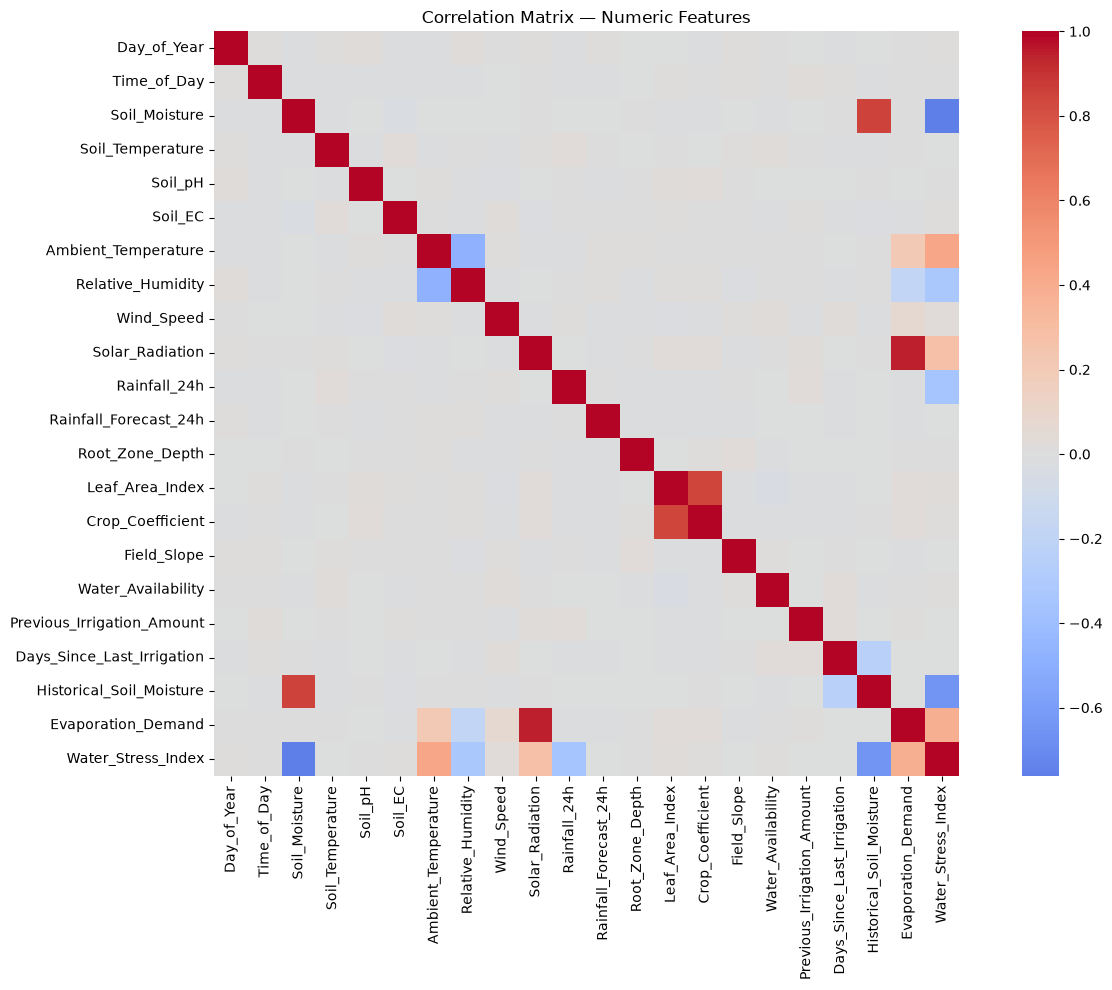

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = df.select_dtypes(include=[np.number]).columns.drop("Field_ID")
corr = df[num_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Correlation Matrix — Numeric Features")
plt.tight_layout()
plt.show()

In [10]:
# Numeric features only, grouped by target
key_feats = ["Soil_Moisture", "Water_Stress_Index", "Evaporation_Demand",
             "Rainfall_24h", "Previous_Irrigation_Amount", "Days_Since_Last_Irrigation"]

df.groupby("Irrigation_Action")[key_feats].mean().round(2)

,Soil_Moisture,Water_Stress_Index,Evaporation_Demand,Rainfall_24h,Previous_Irrigation_Amount,Days_Since_Last_Irrigation
Irrigation_Action,,,,,,
High,28.35,86.56,52.97,4.12,13.95,7.35
Low,36.80,72.72,44.05,6.92,14.10,7.04
Medium,33.38,78.58,47.10,5.11,13.74,6.93
No_Irrigation,40.08,64.22,38.57,13.81,13.70,6.78


In [11]:
from sklearn.preprocessing import LabelEncoder

# Drop ID column
df = df.drop(columns=["Field_ID"])

# Encode target with explicit order
target_order = {"No_Irrigation": 0, "Low": 1, "Medium": 2, "High": 3}
df["Irrigation_Action"] = df["Irrigation_Action"].map(target_order)

print("Target mapping:", target_order)
print("\nTarget values after encoding:")
print(df["Irrigation_Action"].value_counts().sort_index())
print("\nNew shape:", df.shape)

Target mapping: {'No_Irrigation': 0, 'Low': 1, 'Medium': 2, 'High': 3}

Target values after encoding:
Irrigation_Action
0    1684
1    1694
2    1707
3    1707
Name: count, dtype: int64

New shape: (6792, 26)


In [12]:
# Ordinal encoding for Growth_Stage
stage_order = {"Seedling": 0, "Vegetative": 1, "Flowering": 2, "Fruiting": 3, "Maturity": 4}
df["Growth_Stage"] = df["Growth_Stage"].map(stage_order)

# One-hot encode Crop_Type and Soil_Type
df = pd.get_dummies(df, columns=["Crop_Type", "Soil_Type"], drop_first=False)

print("Shape after encoding:", df.shape)
print("\nNew columns added:")
print([c for c in df.columns if c.startswith(("Crop_Type_", "Soil_Type_"))])
print("\nAny missing values?", df.isnull().sum().sum())

Shape after encoding: (6792, 36)

New columns added:
['Crop_Type_Cotton', 'Crop_Type_Groundnut', 'Crop_Type_Maize', 'Crop_Type_Rice', 'Crop_Type_Soybean', 'Crop_Type_Sugarcane', 'Crop_Type_Tomato', 'Crop_Type_Wheat', 'Soil_Type_Clay', 'Soil_Type_Loamy', 'Soil_Type_Sandy', 'Soil_Type_Silty']

Any missing values? 0


In [13]:
# Day_of_Year (1–365)
df["Day_sin"] = np.sin(2 * np.pi * df["Day_of_Year"] / 365)
df["Day_cos"] = np.cos(2 * np.pi * df["Day_of_Year"] / 365)

# Time_of_Day (0–23)
df["Time_sin"] = np.sin(2 * np.pi * df["Time_of_Day"] / 24)
df["Time_cos"] = np.cos(2 * np.pi * df["Time_of_Day"] / 24)

# Drop original columns
df = df.drop(columns=["Day_of_Year", "Time_of_Day"])

print("Shape:", df.shape)
print("\nSample cyclical values:")
print(df[["Day_sin", "Day_cos", "Time_sin", "Time_cos"]].head().round(3))

Shape: (6792, 38)

Sample cyclical values:
   Day_sin  Day_cos  Time_sin  Time_cos
0   -0.850    0.527    -0.866    -0.500
1    0.999    0.039    -0.259    -0.966
2    0.456   -0.890    -0.500    -0.866
3   -0.764   -0.645    -0.500    -0.866
4   -0.180   -0.984    -0.500    -0.866


In [14]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["Irrigation_Action"])
y = df["Irrigation_Action"]

# Stratified split (preserves class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain target distribution:")
print(y_train.value_counts().sort_index())
print("\nTest target distribution:")
print(y_test.value_counts().sort_index())

Train shape: (5433, 37)
Test shape: (1359, 37)

Train target distribution:
Irrigation_Action
0    1347
1    1355
2    1365
3    1366
Name: count, dtype: int64

Test target distribution:
Irrigation_Action
0    337
1    339
2    342
3    341
Name: count, dtype: int64


In [15]:
from sklearn.preprocessing import StandardScaler
import joblib

# Fit scaler on TRAIN only (avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save scaler for later (FastAPI deployment)
joblib.dump(scaler, "scaler.pkl")

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)
print("\nMean (should be ~0):", X_train_scaled.mean().round(3))
print("Std (should be ~1):", X_train_scaled.std().round(3))

X_train_scaled shape: (5433, 37)
X_test_scaled shape: (1359, 37)

Mean (should be ~0): -0.0
Std (should be ~1): 1.0


In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import time

# Train
start = time.time()
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
train_time = time.time() - start

# Predict
y_pred_rf = rf.predict(X_test)

# Evaluate
acc_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average="macro")

print(f"Training time: {train_time:.2f}s")
print(f"Accuracy:  {acc_rf:.4f}")
print(f"Macro-F1:  {f1_rf:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf,
      target_names=["No_Irrigation", "Low", "Medium", "High"]))

Training time: 0.63s
Accuracy:  0.4967
Macro-F1:  0.4930

Classification Report:
               precision    recall  f1-score   support

No_Irrigation       0.61      0.66      0.63       337
          Low       0.37      0.34      0.35       339
       Medium       0.38      0.36      0.37       342
         High       0.60      0.62      0.61       341

     accuracy                           0.50      1359
    macro avg       0.49      0.50      0.49      1359
 weighted avg       0.49      0.50      0.49      1359



In [17]:
import pandas as pd

# Feature importances
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False)

print("Top 15 features:")
print(importances.head(15).round(4))

print("\nBottom 10 features (near-zero):")
print(importances.tail(10).round(4))

Top 15 features:
Water_Stress_Index            0.1196
Soil_Moisture                 0.0710
Rainfall_Forecast_24h         0.0539
Evaporation_Demand            0.0509
Rainfall_24h                  0.0503
Historical_Soil_Moisture      0.0503
Solar_Radiation               0.0462
Ambient_Temperature           0.0352
Water_Availability            0.0340
Relative_Humidity             0.0328
Wind_Speed                    0.0324
Previous_Irrigation_Amount    0.0323
Field_Slope                   0.0320
Soil_EC                       0.0320
Soil_pH                       0.0320
dtype: float64

Bottom 10 features (near-zero):
Soil_Type_Loamy        0.0045
Crop_Type_Rice         0.0042
Crop_Type_Maize        0.0040
Soil_Type_Silty        0.0038
Crop_Type_Wheat        0.0037
Crop_Type_Soybean      0.0036
Crop_Type_Cotton       0.0034
Crop_Type_Tomato       0.0034
Crop_Type_Groundnut    0.0032
Crop_Type_Sugarcane    0.0028
dtype: float64


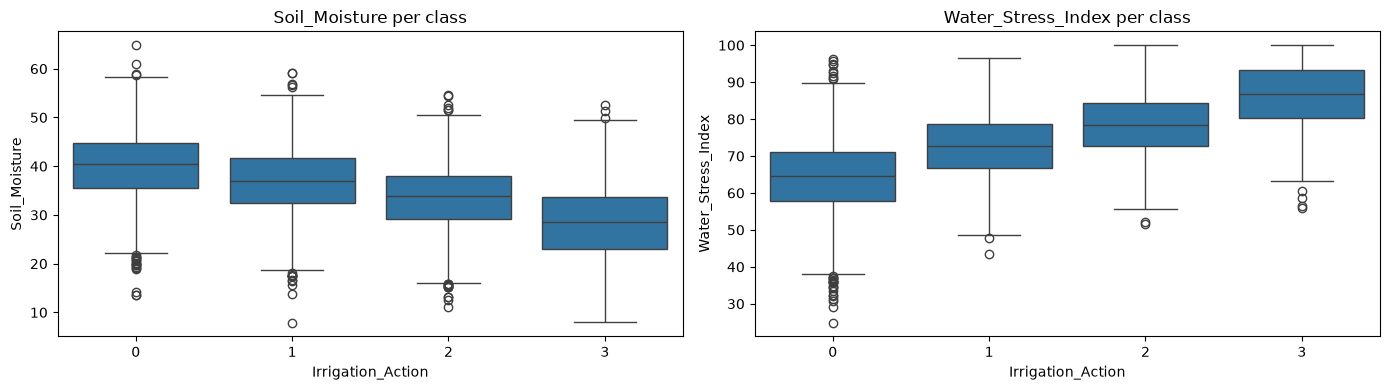

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(data=df, x="Irrigation_Action", y="Soil_Moisture", ax=axes[0])
axes[0].set_title("Soil_Moisture per class")

sns.boxplot(data=df, x="Irrigation_Action", y="Water_Stress_Index", ax=axes[1])
axes[1].set_title("Water_Stress_Index per class")

plt.tight_layout()
plt.show()

In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Train regressor
rf_reg = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_train)

# Predict continuous values
y_pred_cont = rf_reg.predict(X_test)

# Round to nearest class (0–3)
y_pred_ord = np.clip(np.round(y_pred_cont), 0, 3).astype(int)

# Evaluate
mae = mean_absolute_error(y_test, y_pred_cont)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_cont))
acc = accuracy_score(y_test, y_pred_ord)
f1 = f1_score(y_test, y_pred_ord, average="macro")

# Adjacent accuracy (within ±1)
adj_acc = np.mean(np.abs(y_test - y_pred_ord) <= 1)

print(f"MAE:              {mae:.4f}")
print(f"RMSE:             {rmse:.4f}")
print(f"Accuracy (rounded): {acc:.4f}")
print(f"Macro-F1:         {f1:.4f}")
print(f"Adjacent accuracy (±1): {adj_acc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_ord,
      target_names=["No_Irrigation", "Low", "Medium", "High"]))

MAE:              0.6236
RMSE:             0.7831
Accuracy (rounded): 0.4842
Macro-F1:         0.4915
Adjacent accuracy (±1): 0.9433

Classification Report:
               precision    recall  f1-score   support

No_Irrigation       0.79      0.43      0.56       337
          Low       0.40      0.54      0.46       339
       Medium       0.37      0.60      0.46       342
         High       0.72      0.37      0.49       341

     accuracy                           0.48      1359
    macro avg       0.57      0.48      0.49      1359
 weighted avg       0.57      0.48      0.49      1359



In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# Train 3 binary classifiers: y>0, y>1, y>2
models = {}
for threshold in [0, 1, 2]:
    y_bin_train = (y_train > threshold).astype(int)
    clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    clf.fit(X_train, y_bin_train)
    models[threshold] = clf
    auc = roc_auc_score((y_test > threshold).astype(int),
                        clf.predict_proba(X_test)[:, 1])
    print(f"P(y > {threshold}) — AUC: {auc:.4f}")

# Predict ordinal score = sum of probabilities
probs = np.column_stack([models[t].predict_proba(X_test)[:, 1] for t in [0, 1, 2]])
y_pred_ord2 = np.clip(np.round(probs.sum(axis=1)), 0, 3).astype(int)

# Evaluate
mae2 = mean_absolute_error(y_test, probs.sum(axis=1))
acc2 = accuracy_score(y_test, y_pred_ord2)
adj_acc2 = np.mean(np.abs(y_test - y_pred_ord2) <= 1)

print(f"\n--- Ordinal decomposition ---")
print(f"MAE:              {mae2:.4f}")
print(f"Accuracy:         {acc2:.4f}")
print(f"Adjacent accuracy: {adj_acc2:.4f}")

P(y > 0) — AUC: 0.8728
P(y > 1) — AUC: 0.8708
P(y > 2) — AUC: 0.8525

--- Ordinal decomposition ---
MAE:              0.6410
Accuracy:         0.4673
Adjacent accuracy: 0.9500


In [21]:
from xgboost import XGBRegressor, XGBClassifier

# A1-style: XGBoost regressor
xgb_reg = XGBRegressor(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    random_state=42, n_jobs=-1
)
xgb_reg.fit(X_train, y_train)
y_pred_xgb_reg = np.clip(np.round(xgb_reg.predict(X_test)), 0, 3).astype(int)

mae_xgb = mean_absolute_error(y_test, xgb_reg.predict(X_test))
acc_xgb = accuracy_score(y_test, y_pred_xgb_reg)
adj_acc_xgb = np.mean(np.abs(y_test - y_pred_xgb_reg) <= 1)

print("--- XGBoost Regressor (ordinal) ---")
print(f"MAE:              {mae_xgb:.4f}")
print(f"Accuracy:         {acc_xgb:.4f}")
print(f"Adjacent accuracy: {adj_acc_xgb:.4f}")

# Baseline classification for reference
xgb_clf = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    random_state=42, n_jobs=-1
)
xgb_clf.fit(X_train, y_train)
y_pred_xgb_clf = xgb_clf.predict(X_test)

print("\n--- XGBoost Classifier (nominal) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_xgb_clf):.4f}")
print(f"Macro-F1:  {f1_score(y_test, y_pred_xgb_clf, average='macro'):.4f}")

--- XGBoost Regressor (ordinal) ---
MAE:              0.6238
Accuracy:         0.4820
Adjacent accuracy: 0.9426

--- XGBoost Classifier (nominal) ---
Accuracy:  0.4923
Macro-F1:  0.4899


In [22]:
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import mean_absolute_error

# MLP Regressor (ordinal)
mlp_reg = MLPRegressor(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=1e-4,           # L2 regularization
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    random_state=42
)
mlp_reg.fit(X_train_scaled, y_train)

y_pred_mlp_reg = np.clip(np.round(mlp_reg.predict(X_test_scaled)), 0, 3).astype(int)
mae_mlp = mean_absolute_error(y_test, mlp_reg.predict(X_test_scaled))
acc_mlp = accuracy_score(y_test, y_pred_mlp_reg)
adj_acc_mlp = np.mean(np.abs(y_test - y_pred_mlp_reg) <= 1)

print("--- MLP Regressor (ordinal, scaled data) ---")
print(f"MAE:              {mae_mlp:.4f}")
print(f"Accuracy:         {acc_mlp:.4f}")
print(f"Adjacent accuracy: {adj_acc_mlp:.4f}")
print(f"Training epochs:  {mlp_reg.n_iter_}")

--- MLP Regressor (ordinal, scaled data) ---
MAE:              0.6252
Accuracy:         0.4960
Adjacent accuracy: 0.9411
Training epochs:  24


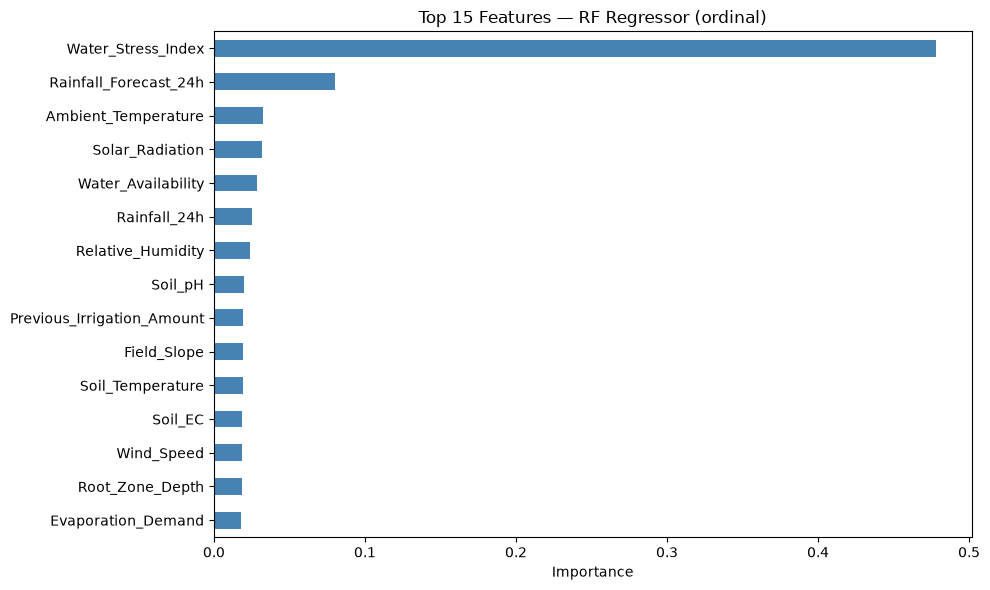

Water_Stress_Index            0.4779
Rainfall_Forecast_24h         0.0803
Ambient_Temperature           0.0323
Solar_Radiation               0.0319
Water_Availability            0.0287
Rainfall_24h                  0.0251
Relative_Humidity             0.0238
Soil_pH                       0.0198
Previous_Irrigation_Amount    0.0195
Field_Slope                   0.0193
Soil_Temperature              0.0191
Soil_EC                       0.0189
Wind_Speed                    0.0188
Root_Zone_Depth               0.0184
Evaporation_Demand            0.0182
dtype: float64


In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Feature importances from RF Regressor
imp_reg = pd.Series(rf_reg.feature_importances_, index=X_train.columns)
imp_reg = imp_reg.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
imp_reg.plot(kind="barh", color="steelblue")
plt.gca().invert_yaxis()
plt.title("Top 15 Features — RF Regressor (ordinal)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(imp_reg.round(4))

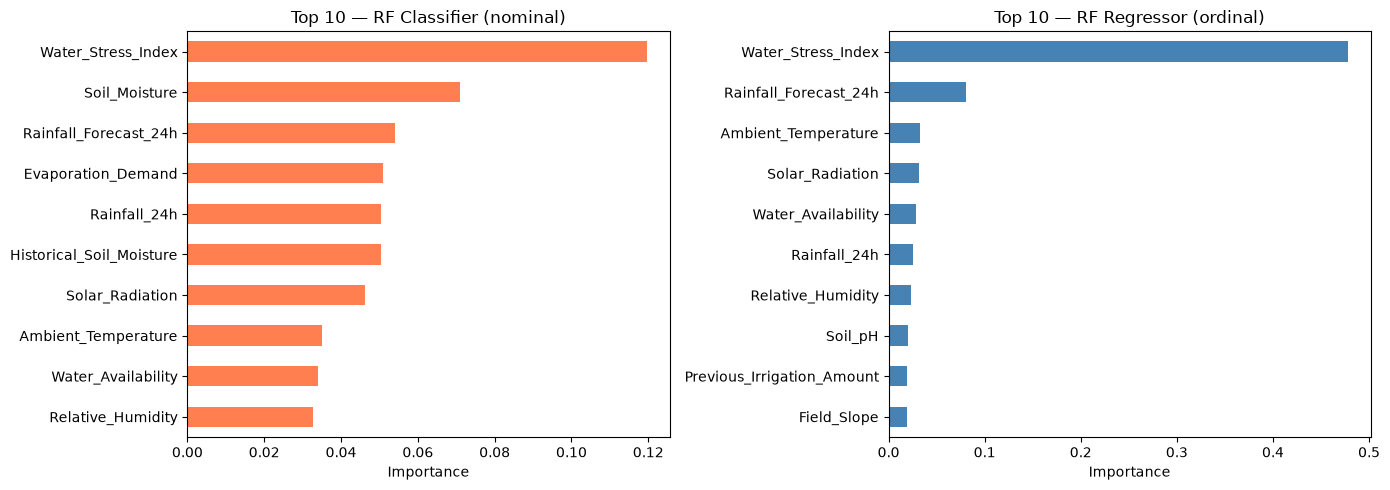

In [24]:
# Classifier importances (from Cell 15b)
imp_clf = pd.Series(rf.feature_importances_, index=X_train.columns)

# Regressor importances
imp_reg_full = pd.Series(rf_reg.feature_importances_, index=X_train.columns)

# Top 10 from each
top_clf = imp_clf.sort_values(ascending=False).head(10)
top_reg = imp_reg_full.sort_values(ascending=False).head(10)

# Side-by-side bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_clf.plot(kind="barh", ax=axes[0], color="coral")
axes[0].invert_yaxis()
axes[0].set_title("Top 10 — RF Classifier (nominal)")
axes[0].set_xlabel("Importance")

top_reg.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].invert_yaxis()
axes[1].set_title("Top 10 — RF Regressor (ordinal)")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()

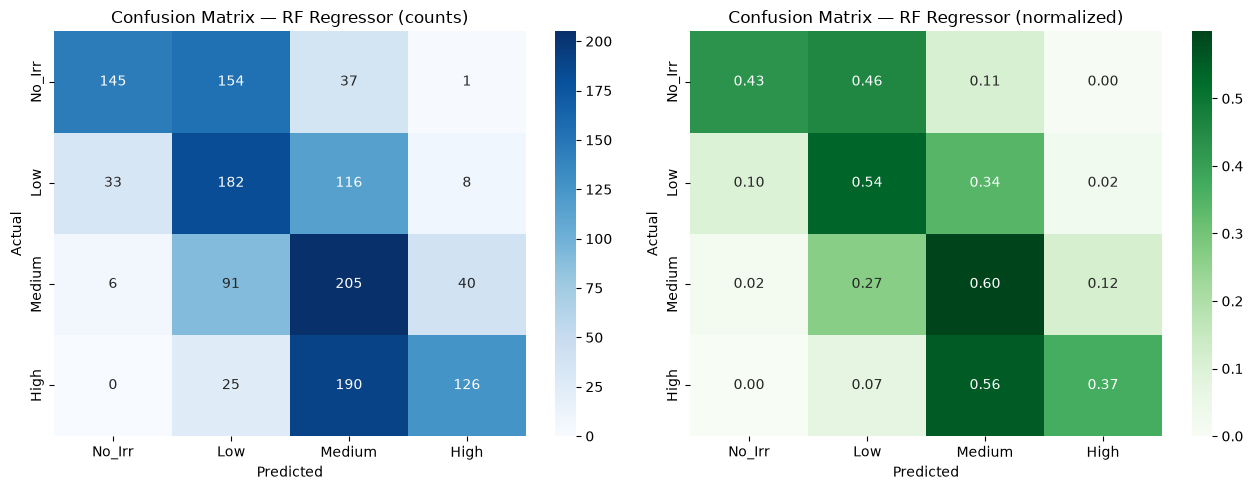

In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_ord)
labels = ["No_Irr", "Low", "Medium", "High"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Raw counts
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title("Confusion Matrix — RF Regressor (counts)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Normalized
cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens",
            xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title("Confusion Matrix — RF Regressor (normalized)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

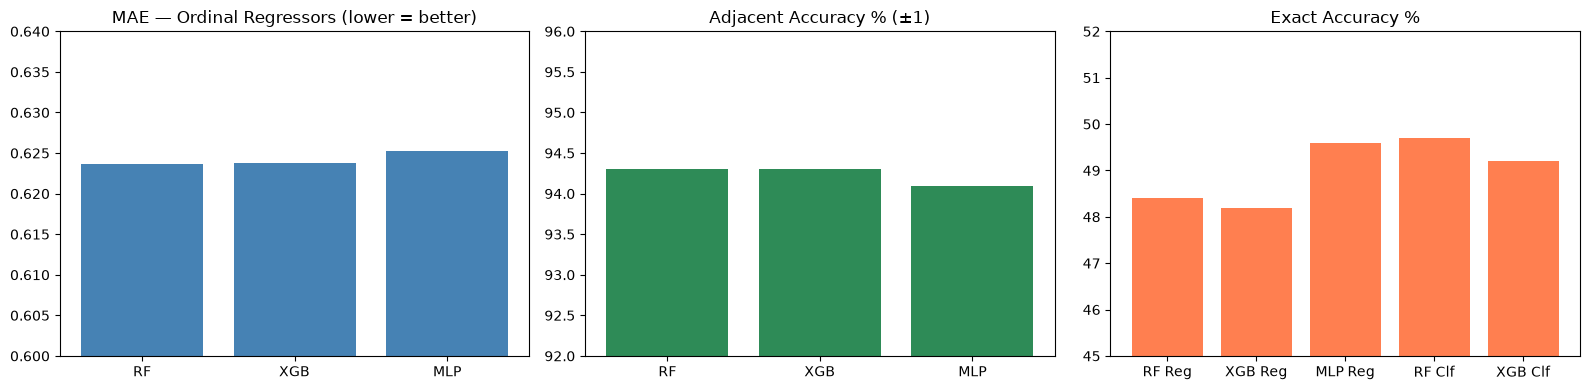

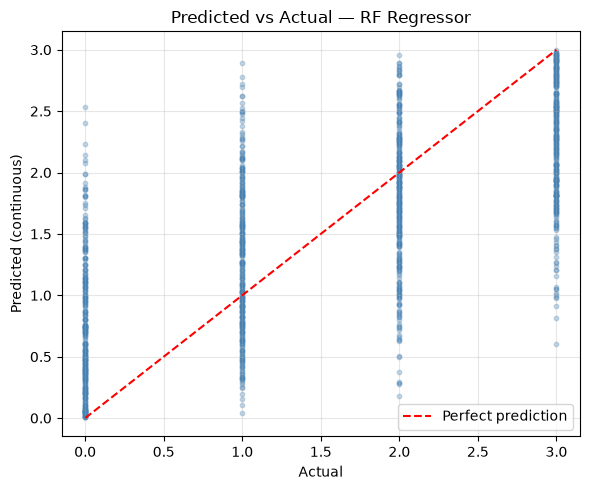

In [26]:
# Model comparison data
models = ["RF Reg", "XGB Reg", "MLP Reg", "RF Clf", "XGB Clf"]
mae_vals = [0.6236, 0.6238, 0.6252, None, None]
adj_vals = [94.3, 94.3, 94.1, None, None]
acc_vals = [48.4, 48.2, 49.6, 49.7, 49.2]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# MAE (lower better)
axes[0].bar(["RF", "XGB", "MLP"], [0.6236, 0.6238, 0.6252], color="steelblue")
axes[0].set_title("MAE — Ordinal Regressors (lower = better)")
axes[0].set_ylim(0.60, 0.64)

# Adjacent accuracy
axes[1].bar(["RF", "XGB", "MLP"], [94.3, 94.3, 94.1], color="seagreen")
axes[1].set_title("Adjacent Accuracy % (±1)")
axes[1].set_ylim(92, 96)

# Exact accuracy
axes[2].bar(models, acc_vals, color="coral")
axes[2].set_title("Exact Accuracy %")
axes[2].set_ylim(45, 52)

plt.tight_layout()
plt.show()

# Predicted vs actual scatter (RF Regressor)
plt.figure(figsize=(6, 5))
plt.scatter(y_test, rf_reg.predict(X_test), alpha=0.3, s=10, color="steelblue")
plt.plot([0, 3], [0, 3], "r--", label="Perfect prediction")
plt.xlabel("Actual")
plt.ylabel("Predicted (continuous)")
plt.title("Predicted vs Actual — RF Regressor")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
import joblib

# Save RF Regressor + scaler (scaler still needed for pipeline consistency)
joblib.dump(rf_reg, "models/rf_regressor.pkl")
joblib.dump(scaler, "models/scaler.pkl")

# Save feature column order (critical for inference)
feature_cols = list(X_train.columns)
joblib.dump(feature_cols, "models/feature_columns.pkl")

print("Saved:")
print("  models/rf_regressor.pkl")
print("  models/scaler.pkl")
print("  models/feature_columns.pkl")
print(f"\nTotal features: {len(feature_cols)}")

Saved:
  models/rf_regressor.pkl
  models/scaler.pkl
  models/feature_columns.pkl

Total features: 37
